# Part 1: Machine learning and CNNs

**Build a CNN that predicts AGO2 binding, and look inside it**

**Technion AI Days 2026: Applications of AI in Biotechnology and Genomics**

**AGO2** is a protein that carries a small RNA, a microRNA, and binds RNA molecules that pair with
that microRNA. **CLIP-seq** measures where it binds: UV light crosslinks proteins to the RNA they
touch, an antibody pulls down AGO2, and the RNA fragments attached to it are sequenced.

**The data.** We use the AGO2 set of the GraphProt CLIP benchmark (Maticzka et al. 2014), as used by
Pan & Shen (2018). Each **bound** sequence contains a CLIP-seq binding site of about 40 letters, with
flanking context on both sides (in the files the site is in capital letters and the context in small
letters; we convert everything to capitals). Each **unbound** sequence was made by moving a binding
site to a random position in the same gene. The files call the two classes *positives* and
*negatives*.

In this notebook you will:

1. build and train a model that takes an RNA sequence and estimates the probability that AGO2
   binds it, $f(\text{sequence}) = P(\text{bound} \mid \text{sequence})$;
2. read off the letter patterns that its first-layer filters respond to, as sequence logos;
3. test one of these patterns by inserting it into random RNA, next to a shuffled control.


**How this notebook works**

| cell | what you do |
|---|---|
| `#@title ... run this cell, nothing to change` | run it (Shift+Enter) |
| `# TODO-N` with `# === Your code here ===` | write the code yourself (replace the `...`) |
| `#@title Test TODO-N ...` | run it: it checks your code and says what is wrong |
| `#@title Stuck? ...` | run it only if the test of your TODO fails: it defines our version |

Before you start: *Runtime → Change runtime type → T4 GPU*.

## 0. Setup

Run the next two cells. The first one also installs `logomaker`, which draws the sequence logos in
section 7.

In [1]:
#@title Setup - run this cell, nothing to change { display-mode: "form" }
import os, time, urllib.request
_SETUP_T0 = time.time()   # when this cell started; used only by the optional timing log at the end
from pathlib import Path
import numpy as np
import torch
from torch import nn, optim
from sklearn.metrics import roc_auc_score

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU - Runtime > Change runtime type > T4 GPU")

FORCE_FP16 = os.environ.get("AIDAYS_FORCE_FP16") == "1"
AMP_DTYPE = (torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported() and not FORCE_FP16
             else torch.float16)

# Plot style, shared by every notebook (the same palette as the slides).
import logging
import matplotlib.pyplot as plt
from matplotlib import cycler
from matplotlib.colors import LinearSegmentedColormap

INK, MUTED, MIDGREY, LIGHTGREY, HAIRLINE = "#202124", "#5F6368", "#80868B", "#C4C7C5", "#DADCE0"
ACCENT = "#1A73E8"
# The accent (blue) marks only bound sequences and fine-tuned models; everything else is ink or grey.
BOUND, UNBOUND = ACCENT, LIGHTGREY                            # class colours
CNN_C, FROZEN_C, FINETUNED_C, BASELINE_C = INK, MIDGREY, ACCENT, MIDGREY   # model colours (baselines dashed)
BASE_COLOURS = {"A": "#0F9D58", "C": "#4285F4", "G": "#F4B400", "U": "#DB4437", "T": "#DB4437"}  # logos only
CMAP_DIV = LinearSegmentedColormap.from_list("ws_div", [MUTED, "#FFFFFF", ACCENT])         # weight heatmaps
CMAP_SEQ = LinearSegmentedColormap.from_list("ws_seq", [HAIRLINE, MIDGREY, INK])          # sequential values: grey -> ink

plt.colormaps.register(CMAP_SEQ, force=True)
plt.colormaps.register(CMAP_DIV, force=True)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # Colab has no Roboto: fall back quietly
plt.rcParams.update({
    "font.family": ["Roboto", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.prop_cycle": cycler(color=[INK, MIDGREY, LIGHTGREY]),
    "axes.grid": False, "grid.color": HAIRLINE, "grid.linewidth": 0.8,
    "legend.frameon": False, "legend.fontsize": 8,
    "image.cmap": "ws_seq",
})

# Where the workshop files are stored. Either one direct-download link per file (FILE_URLS, e.g. SharePoint
# "anyone with the link" + download=1), or one folder URL (DATA_URL, e.g. a Hugging Face dataset repo).
FILE_URLS = {}
DATA_URL = os.environ.get("AIDAYS_DATA_URL", "https://huggingface.co/datasets/yup8/ai-days-2026-ago2/resolve/main")
DATA_DIR = Path(os.environ.get("AIDAYS_DATA_DIR", "data"))
DATA_DIR.mkdir(exist_ok=True)

try:
    from google.colab import files as _colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def fetch(name):
    """Return the local path of a workshop file, downloading it first if needed."""
    path = DATA_DIR / name
    if not path.exists():
        url = FILE_URLS.get(name) or (f"{DATA_URL.rstrip('/')}/{name}" if DATA_URL else "")
        if not url:
            raise FileNotFoundError(f"{path} not found and no download link is set for it")
        t = time.time()
        urllib.request.urlretrieve(url, path)
        print(f"downloaded {name} ({path.stat().st_size / 1e6:.1f} MB) in {time.time() - t:.1f}s")
    return path


def download_outputs(*names):
    """End of a notebook: save your results to your laptop so the next notebook can use them."""
    for n in names:
        p = DATA_DIR / n
        if not p.exists():
            print(f"{n}: not found (did the cell that makes it run?)")
        elif IN_COLAB and os.environ.get("AIDAYS_NO_DOWNLOAD") != "1":   # AIDAYS_NO_DOWNLOAD=1: automated test runs
            _colab_files.download(str(p))
        else:
            print(f"{n}: saved at {p}")


def upload_yours():
    """Start of a notebook: upload the files you downloaded at the end of an earlier notebook."""
    if not IN_COLAB:
        print(f"not in Colab: copy your files into {DATA_DIR}")
        return
    import re
    for n, b in _colab_files.upload().items():
        clean = re.sub(r" \(\d+\)(?=\.[^.]+$)", "", n)   # "my_cnn (1).pt" -> "my_cnn.pt" (browser renames)
        (DATA_DIR / clean).write_bytes(b)
        print("uploaded", n, "->", clean)


def _aidays_timing():
    """Optional cell timer for testing the notebooks. It does nothing unless the environment variable
    AIDAYS_TIMING=1 is set. Then every executed cell appends {first_line, seconds, raised, error_type,
    error_message} to the list builtins.__AIDAYS_LOG__, which survives reruns of this cell."""
    if os.environ.get("AIDAYS_TIMING") != "1":
        return
    try:
        import builtins
        import time as _t
        from IPython import get_ipython
        if not isinstance(getattr(builtins, "__AIDAYS_LOG__", None), list):
            builtins.__AIDAYS_LOG__ = []
        ip = get_ipython()
        if ip is None or getattr(builtins, "__AIDAYS_HOOKED__", False):
            return

        def pre(info=None):
            try:
                builtins.__AIDAYS_T0__ = _t.time()
            except Exception:
                pass

        def post(result=None):
            try:
                t0, builtins.__AIDAYS_T0__ = getattr(builtins, "__AIDAYS_T0__", None), None
                src = getattr(getattr(result, "info", None), "raw_cell", None) or ""
                err = getattr(result, "error_in_exec", None) or getattr(result, "error_before_exec", None)
                if not isinstance(getattr(builtins, "__AIDAYS_LOG__", None), list):
                    builtins.__AIDAYS_LOG__ = []
                builtins.__AIDAYS_LOG__.append({
                    "first_line": next((l.strip() for l in src.splitlines() if l.strip()), "")[:120],
                    "seconds": None if t0 is None else round(_t.time() - t0, 2),
                    "raised": err is not None,
                    "error_type": None if err is None else type(err).__name__,
                    "error_message": None if err is None else str(err)[:500]})
            except Exception:
                pass

        ip.events.register("pre_run_cell", pre)
        ip.events.register("post_run_cell", post)
        builtins.__AIDAYS_HOOKED__ = True
        builtins.__AIDAYS_T0__ = globals().get("_SETUP_T0") or _t.time()   # time this setup cell from its start
        print("timing log on: builtins.__AIDAYS_LOG__")
    except Exception:
        pass


_aidays_timing()
!pip -q install logomaker==0.8.7

device: cuda | NVIDIA A30


In [2]:
#@title Data helpers - run this cell, nothing to change { display-mode: "form" }
MAX_LEN  = 501          # fixed global length (pad / truncate)
ALPHABET = "ACGU"       # order = the 4 rows of the one-hot matrix
FILES = {split: (f"CLIPSEQ_AGO2.{split}.positives.fa", f"CLIPSEQ_AGO2.{split}.negatives.fa")
         for split in ("train", "ls")}


def read_fasta(path, label):
    """Return (sequences, labels) from a FASTA file, all with the same label.

    The files mix the DNA letter T and the RNA letter U for the same base,
    so we normalise everything to U.
    """
    seqs, labs = [], []
    with Path(path).open() as fh:
        for line in fh:
            if line.startswith(">"):
                continue
            seqs.append(line.strip().upper().replace("T", "U"))
            labs.append(label)
    return seqs, labs


def read_split(split):
    """'train' or 'ls' (the held-out test set) -> (sequences, labels as a numpy array)."""
    pos, neg = FILES[split]
    p, lp = read_fasta(fetch(pos), 1)
    n, ln = read_fasta(fetch(neg), 0)
    return p + n, np.array(lp + ln)

# Build a CNN (sections 1 to 5)

## 1. The data

Each sequence is a string over the 4-letter RNA alphabet `A C G U`. The *train* files are used to
fit the model. The *ls* files hold 1,000 other sequences, the **held-out test set**, which we use only
for evaluation.

In [3]:
#@title Load the sequences - run this cell, nothing to change { display-mode: "form" }
train_seqs, train_y = read_split("train")
test_seqs, test_y = read_split("ls")
print(f"train: {len(train_seqs):,} sequences ({train_y.mean():.0%} bound)")
print(f"test : {len(test_seqs):,} sequences ({test_y.mean():.0%} bound)")
print(f"length: {min(map(len, train_seqs))}-{max(map(len, train_seqs))} letters")
print("\na bound sequence:\n", train_seqs[0][:90], "...")

train: 92,346 sequences (52% bound)
test : 1,000 sequences (50% bound)
length: 137-375 letters

a bound sequence:
 GGACAGAAGGGUAUAGAAAAGUCCCCUACCAUUAUUAUGAACAAGGAAGAGAUGAGUGUGAUGAAUAUUUUCUUCAUGAACAUGCCCCAU ...


## 2. One-hot encoding: a sequence becomes a matrix (TODO-1)

The model takes numbers as input. We encode each letter as a column of 4 numbers: 1 in the row of
that letter and 0 elsewhere (rows = `A, C, G, U`). A sequence of length $L$ becomes a $4 \times L$ matrix,
which we treat as a one-channel image of height 4.

Every input has the same width, 501 columns, the input size used by Pan & Shen. Our sequences are
137 to 375 letters long, so the remaining columns are padding: columns of 0.25 (equal weight on all
four letters).

You will write this conversion in two steps: first for one sequence, then for a batch of sequences.

In [4]:
#@title One sequence and the alphabet - run this cell, nothing to change { display-mode: "form" }
s = train_seqs[0]
print("first 10 letters:", s[:10], "| length:", len(s))
print("ALPHABET =", repr(ALPHABET), "| the row of each letter:", {b: ALPHABET.index(b) for b in ALPHABET})
print("MAX_LEN  =", MAX_LEN, "columns per sequence")

first 10 letters: GGACAGAAGG | length: 340
ALPHABET = 'ACGU' | the row of each letter: {'A': 0, 'C': 1, 'G': 2, 'U': 3}
MAX_LEN  = 501 columns per sequence


In [5]:
# TODO-1a: write one_hot(seq), which turns ONE sequence into its one-hot matrix, a numpy array with
#          4 rows (A, C, G, U, in the order of ALPHABET) and MAX_LEN columns, one column per letter.
#          - the column of a letter has a 1 in that letter's row and 0 in the other three rows
#          - every column after the end of the sequence is padding: 0.25 in all four rows
#          - a letter other than A, C, G or U also gets a column of 0.25
def one_hot(seq):
    # === Your code here ===
    ...
    # === End of your code ===


M = one_hot(train_seqs[0])
L = len(train_seqs[0])
print("shape:", M.shape, "(rows, columns)")
print("letters:", "  ".join(train_seqs[0][:8]))
print(M[:, :8])
print(f"columns {L - 1} and {L} (the last letter, then the first padding column):")
print(M[:, L - 1:L + 1])

AttributeError: 'NoneType' object has no attribute 'shape'

In [6]:
# TODO-1b: write encode_batch(seqs), which turns a list of N sequences into one input for the CNN:
#          the one-hot matrices of all N sequences, stacked, as a PyTorch tensor of floats with the shape
#          (N, 1, 4, MAX_LEN). The CNN reads each matrix like a one-colour image, and the axis of size 1
#          is that single colour channel.
def encode_batch(seqs):
    # === Your code here ===
    ...
    # === End of your code ===


X3 = encode_batch(train_seqs[:3])
print("shape:", tuple(X3.shape), "(sequences, channel, rows, columns) | type:", X3.dtype)

AttributeError: 'NoneType' object has no attribute 'shape'

In [7]:
#@title Test your encoding - run this cell, nothing to change { display-mode: "form" }
def test_encoding():
    rng = np.random.default_rng(0)
    seqs = [train_seqs[i] for i in rng.choice(len(train_seqs), 200, replace=False)] + ["ACGUN"]
    X = encode_batch(seqs)
    assert tuple(X.shape) == (len(seqs), 1, 4, MAX_LEN), f"shape {tuple(X.shape)}, want {(len(seqs), 1, 4, MAX_LEN)}"
    assert X.dtype == torch.float32, f"dtype {X.dtype}, want torch.float32"
    X = X.numpy()
    for n, s in enumerate(seqs):
        L = min(len(s), MAX_LEN)
        for i, b in enumerate(s[:L]):
            want = np.eye(4)[ALPHABET.index(b)] if b in ALPHABET else np.full(4, 0.25)
            assert np.allclose(X[n, 0, :, i], want), f"sequence {n!r}, column {i} (letter {b}): {X[n, 0, :, i]}, want {want}"
        assert np.allclose(X[n, 0, :, L:], 0.25), f"sequence {n}: the padding columns after letter {L} should all be 0.25"
    print(f"TODO-1 passed: {len(seqs)} sequences encoded correctly (including a letter N, which stays 0.25)")


test_encoding()

AttributeError: 'NoneType' object has no attribute 'shape'

In [8]:
#@title Stuck? Run this only if the test failed: it defines our one_hot and encode_batch { display-mode: "form" }
def one_hot(seq):
    M = np.full((4, MAX_LEN), 0.25, dtype=np.float32)
    for i, b in enumerate(seq[:MAX_LEN]):
        if b in ALPHABET:
            M[:, i] = 0.0
            M[ALPHABET.index(b), i] = 1.0
    return M


def encode_batch(seqs):
    return torch.from_numpy(np.stack([one_hot(s) for s in seqs])[:, None])


test_encoding()

TODO-1 passed: 201 sequences encoded correctly (including a letter N, which stays 0.25)


In [9]:
#@title A faster encode_batch for the rest of the notebook - run this cell, nothing to change { display-mode: "form" }
# It gives the same matrices as yours, but looks up all letters of a sequence at once instead of one by
# one, which matters for the 92,346 training sequences.
your_encode_batch = encode_batch
# the fast encode_batch: looks up all letters of a sequence at once
_LUT = np.full(256, -1, dtype=np.int64)
for _i, _b in enumerate(ALPHABET):
    _LUT[ord(_b)] = _i


def encode_batch(seqs, max_len=MAX_LEN):
    """List of RNA strings -> one-hot FloatTensor (B, 1, 4, max_len).

    Pads/truncates to max_len; padding and unknown bases stay uniform 0.25.
    """
    X = np.full((len(seqs), 1, 4, max_len), 0.25, dtype=np.float32)
    for b, s in enumerate(seqs):
        idx = _LUT[np.frombuffer(s[:max_len].encode(), dtype=np.uint8)]
        pos = np.nonzero(idx >= 0)[0]
        X[b, 0, :, pos] = 0.0
        X[b, 0, idx[pos], pos] = 1.0
    return torch.from_numpy(X)
assert torch.equal(your_encode_batch(train_seqs[:100]), encode_batch(train_seqs[:100])), "the fast version differs from yours"
print("the fast encode_batch gives the same matrices as yours on 100 sequences")

the fast encode_batch gives the same matrices as yours on 100 sequences


## 3. The model (TODO-2)

A **convolution** layer computes the dot product of a small weight matrix (a *filter*) with every
window of the input. Our first-layer filters are $4 \times 10$, so each one gives a score to every
10-letter window. The score is high when the window matches the letter pattern stored in the
filter's weights, so each filter responds most strongly to one letter pattern (a candidate **motif**,
a short sequence pattern). Each filter produces one row of output, called a **channel**, so 10
filters give 10 channels.

**ReLU** (`max(0, x)`) sets negative values to 0. **Max pooling** keeps the largest value in each block
of 3 positions. A second convolution combines the first-layer channels. **Flatten** lays all remaining
numbers out in one row, and a final **linear** layer (a weighted sum plus a bias) maps them to one
number per sequence, the **logit**. A logit can be any real number: large and positive means
"bound", large and negative means "unbound". Section 4 turns it into a probability.

The network, layer by layer, for one sequence of width 501 (each step is its own layer):

| layer | what it does | output shape |
|---|---|---|
| input | the one-hot matrix, one channel | `1 × 4 × 501` |
| convolution | 10 filters, each 4 letters × 10 positions | `10 × 1 × 492` |
| ReLU | negative values become 0 | `10 × 1 × 492` |
| max pooling | the largest of every 3 positions | `10 × 1 × 164` |
| convolution | 20 filters, each covering 5 positions of all 10 channels | `20 × 1 × 160` |
| ReLU | negative values become 0 | `20 × 1 × 160` |
| max pooling | the largest of every 3 positions | `20 × 1 × 53` |
| flatten | all 20 × 53 numbers in one row | `1060` |
| linear | a weighted sum of the 1,060 numbers plus a bias | `1` |

In [10]:
class GlobalCNN(nn.Module):
    """One-hot batch (N, 1, 4, 501) -> one raw score (logit) per sequence, shape (N,)."""

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # TODO-2: the layers of the table above, in order.
            # === Your code here ===
            ...
            # === End of your code ===
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


# two sequences in, one score per sequence out
print("output shape for 2 sequences:", tuple(GlobalCNN()(encode_batch(train_seqs[:2])).shape))

TypeError: ellipsis is not a Module subclass

In [11]:
#@title Test TODO-2 - run this cell, nothing to change { display-mode: "form" }
def test_network():
    model = GlobalCNN()
    X = encode_batch(train_seqs[:5])
    rows = ["the first convolution", "the first max pooling", "the second convolution", "the second max pooling",
            "flatten", "the linear layer"]
    want = [(10, 1, 492), (10, 1, 164), (20, 1, 160), (20, 1, 53), (1060,), (1,)]
    # run the batch through self.net one layer at a time and keep the shape after each layer
    # (a ReLU keeps the shape, so a shape is recorded only when it changes)
    shapes, h = [], X
    for i, layer in enumerate(model.net):
        try:
            h = layer(h)
        except Exception as e:
            raise AssertionError(f"layer {i} of self.net, {layer}, fails on an input of shape "
                                 f"{tuple(h.shape)}: {e}") from None
        if not shapes or shapes[-1] != tuple(h.shape[1:]):
            shapes.append(tuple(h.shape[1:]))
    for row, got, w in zip(rows, shapes, want):
        assert got == w, f"after {row} the shape of one sequence is {got}, want {w} (see the table)"
    assert shapes == want, f"the shapes after the layers are {shapes}, want {want}"
    kinds = [type(l).__name__ for l in model.net]
    for i, k in enumerate(kinds):
        if k == "Conv2d":
            assert kinds[i + 1:i + 2] == ["ReLU"], \
                f"layer {i} is a convolution, and the table puts a ReLU right after it; layer {i + 1} is {kinds[i + 1:i + 2]}"
    assert kinds.count("ReLU") == 2, f"the network has {kinds.count('ReLU')} ReLU layers, want 2 (one after each convolution)"
    n = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert n == 2491, f"{n:,} trainable parameters, want 2,491 (410 + 1,020 + 1,061)"
    out = model(X)
    assert tuple(out.shape) == (5,), \
        f"the model's output for 5 sequences has shape {tuple(out.shape)}, want (5,): one logit per sequence"
    print("TODO-2 passed: the shape after every layer matches the table, 2,491 trainable parameters, "
          "output shape (5,) for 5 sequences")


test_network()

TypeError: ellipsis is not a Module subclass

In [12]:
#@title Stuck? Run this only if the test failed: it defines our GlobalCNN { display-mode: "form" }
class GlobalCNN(nn.Module):
    """One-hot batch (N, 1, 4, 501) -> one raw score (logit) per sequence, shape (N,)."""

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 10, (4, 10)), nn.ReLU(),
            nn.MaxPool2d((1, 3)),
            nn.Conv2d(10, 20, (1, 5)), nn.ReLU(),
            nn.MaxPool2d((1, 3)),
            nn.Flatten(),
            nn.Linear(20 * 53, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


test_network()

TODO-2 passed: the shape after every layer matches the table, 2,491 trainable parameters, output shape (5,) for 5 sequences


## 4. Training (TODO-3)

Training minimises a **loss** by gradient descent (here the Adam variant): each step computes the
gradient of the loss on one batch of 256 sequences and moves every weight a small amount against
its gradient. Our loss is binary cross-entropy, the negative log of the probability the model
assigns to the correct label, averaged over the batch. The model outputs a logit $z$; the sigmoid
$\sigma(z) = 1 / (1 + e^{-z})$ turns it into a probability between 0 and 1.

After every pass over the training data (an *epoch*) we evaluate the model on the held-out test
set: the 1,000 `ls` sequences it never trains on. During evaluation the model only scores: no
gradients are computed and the weights do not change. The number we report is **AUROC**: the probability that a randomly chosen bound sequence
gets a higher score than a randomly chosen unbound one. 0.5 is a coin flip, 1.0 is perfect.

The whole training loop, in pseudocode:

```
for each epoch:
    for each batch (X, y) of the training set:
        clear the gradients
        predict: one score (logit) per sequence of X
        loss: compare the scores with the labels y
        gradients: the gradient of the loss for every weight
        step: move every weight against its gradient
    evaluate on the held-out test set:
        no gradients
        probabilities: the sigmoid of the scores
        AUROC of the probabilities against the true labels
```

What each step means:

| step | what it means |
|---|---|
| clear the gradients | forget the gradients of the previous batch |
| predict | the model gives one score (logit) per sequence in the batch |
| loss | one number for the batch: how far the scores are from the labels |
| gradients | for every weight, how much the loss changes when that weight changes |
| step | the optimizer (`opt`) moves every weight a little in the direction that lowers the loss |
| evaluate | score the held-out test set without learning: no gradients, the weights stay as they are |
| probabilities | the sigmoid turns each score into a probability between 0 and 1 |
| AUROC | how well the probabilities separate the bound from the unbound test sequences |

First you run one step by hand on one batch (TODO-3a). Then you write the loop inside `train()`:
the training step (TODO-3b) and the evaluation (TODO-3c).

In [13]:
#@title Encode the training set and cut it into batches - run this cell, nothing to change { display-mode: "form" }
from torch.utils.data import DataLoader, TensorDataset

t0 = time.time()
X_train = encode_batch(train_seqs)
y_train = torch.tensor(train_y, dtype=torch.float32)
print(f"encoded {len(train_seqs):,} sequences in {time.time() - t0:.1f}s")
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=256, shuffle=True, drop_last=True)
print(f"{len(train_loader):,} batches of 256 sequences per epoch")

encoded 92,346 sequences in 1.9s
360 batches of 256 sequences per epoch


In [14]:
X, y = next(iter(train_loader))          # one batch: 256 one-hot sequences and their 256 labels
X, y = X.to(DEVICE), y.to(DEVICE)
torch.manual_seed(SEED)
model = GlobalCNN().to(DEVICE)           # a fresh model with random weights
opt = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()
print("X:", tuple(X.shape), "| y:", tuple(y.shape), "| the first 8 labels:", y[:8].tolist())

# TODO-3a: one training step on this one batch, by hand (the pseudocode above, for one batch).
#          First the prediction and the loss: `logits`, the model's scores for X (one per sequence),
#          and `loss`, the loss of these scores against the labels y (`criterion` is the loss function).
# === Your code here ===
...
# === End of your code ===
print("\nlogits of the first 4 sequences:", [round(v, 3) for v in logits[:4].tolist()])
print("their labels                   :", y[:4].tolist())
print(f"loss before the step: {loss.item():.4f}")

# TODO-3a, continued: clear the gradients, compute the gradients of `loss`, take one optimizer step, and
#          compute the loss on the same batch again with the updated weights (`loss_after`).
# === Your code here ===
...
# === End of your code ===
w = model.net[0].weight
print("\nthe first layer's weights:", tuple(w.shape), "| their gradient, w.grad:", tuple(w.grad.shape),
      "(one number per weight)")
print(f"loss after one step: {loss_after.item():.4f} (before: {loss.item():.4f})")

X: (256, 1, 4, 501) | y: (256,) | the first 8 labels: [0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 1.0]


NameError: name 'logits' is not defined

In [15]:
def train(model, train_loader, test_seqs, test_y, epochs=10, lr=1e-3, wd=1e-4):
    model.to(DEVICE)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    criterion = nn.BCEWithLogitsLoss()
    X_test = encode_batch(test_seqs)
    history = []
    for ep in range(1, epochs + 1):
        t = time.time()
        model.train()
        for X, y in train_loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            # TODO-3b: one training step on the batch X, y (the steps of the pseudocode)
            # === Your code here ===
            ...
            # === End of your code ===

        # TODO-3c: evaluate on the held-out test set (X_test, labels test_y), without learning: the
        #          probability of "bound" for every test sequence, and `auc`, the AUROC of these
        #          probabilities against the true labels.
        # === Your code here ===
        ...
        # === End of your code ===
        history.append(auc)
        print(f"epoch {ep:02d} | held-out test AUROC = {auc:.4f} | {time.time() - t:.1f}s")
    return history

In [16]:
#@title Test TODO-3 - run this cell, nothing to change { display-mode: "form" }
def test_train():
    """Train a fresh model for 1 epoch on 5,000 training sequences and check what train() did."""
    global roc_auc_score
    idx = torch.from_numpy(np.random.default_rng(0).choice(len(X_train), 5000, replace=False))
    small_loader = DataLoader(TensorDataset(X_train[idx], y_train[idx]), batch_size=256, shuffle=True, drop_last=True)
    torch.manual_seed(SEED)
    m = GlobalCNN()
    before = [p.detach().clone() for p in m.parameters()]
    seen, real_roc_auc_score = [], roc_auc_score

    def spy(y_true, y_score):        # keeps what the evaluation passes to roc_auc_score
        seen.append(y_score)
        return real_roc_auc_score(y_true, y_score)

    roc_auc_score = spy
    try:
        hist = train(m, small_loader, test_seqs, test_y, epochs=1)
    finally:
        roc_auc_score = real_roc_auc_score
    assert any(not torch.equal(b, p.detach().cpu()) for b, p in zip(before, m.parameters())), \
        "the weights did not change during training: the training step must compute the gradients and move the weights"
    assert len(seen) == 1, f"roc_auc_score was called {len(seen)} times in 1 epoch, want once per epoch (TODO-3c)"
    p = seen[0]
    assert isinstance(p, np.ndarray), \
        f"roc_auc_score received a {type(p).__name__}, want a numpy array of probabilities"
    assert p.shape == (len(test_seqs),), \
        f"roc_auc_score received scores of shape {p.shape}, want ({len(test_seqs)},): one per held-out test sequence (X_test)"
    assert np.isfinite(p).all(), "the probabilities contain NaN or infinite values"
    assert p.min() >= 0 and p.max() <= 1, \
        (f"the evaluated scores range from {p.min():.2f} to {p.max():.2f}, so they are logits. "
         "Turn them into probabilities between 0 and 1 with the sigmoid")
    assert isinstance(hist, list) and len(hist) == 1, f"train() returned {hist!r}, want a list with one AUROC per epoch"
    assert 0.5 < hist[0] <= 1, f"the AUROC after 1 epoch on 5,000 sequences is {hist[0]:.3f}, want between 0.5 and 1"
    print(f"TODO-3 passed: 1 epoch on 5,000 sequences, held-out test AUROC {hist[0]:.3f}, "
          f"evaluated on {len(p):,} probabilities between {p.min():.2f} and {p.max():.2f}")


test_train()

NameError: name 'auc' is not defined

In [17]:
#@title Stuck? Run this only if the test failed: it defines our train() { display-mode: "form" }
def train(model, train_loader, test_seqs, test_y, epochs=10, lr=1e-3, wd=1e-4):
    model.to(DEVICE)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    criterion = nn.BCEWithLogitsLoss()
    X_test = encode_batch(test_seqs)
    history = []
    for ep in range(1, epochs + 1):
        t = time.time()
        model.train()
        for X, y in train_loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = criterion(model(X), y)
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            probs = torch.sigmoid(model(X_test.to(DEVICE))).cpu().numpy()
        auc = roc_auc_score(test_y, probs)
        history.append(auc)
        print(f"epoch {ep:02d} | held-out test AUROC = {auc:.4f} | {time.time() - t:.1f}s")
    return history


test_train()

epoch 01 | held-out test AUROC = 0.6742 | 0.5s
TODO-3 passed: 1 epoch on 5,000 sequences, held-out test AUROC 0.674, evaluated on 1,000 probabilities between 0.46 and 0.56


In [18]:
#@title Train - run this cell, nothing to change { display-mode: "form" }
EPOCHS = 10
torch.manual_seed(SEED)
model = GlobalCNN()
history = train(model, train_loader, test_seqs, test_y, epochs=EPOCHS)
torch.save(model.state_dict(), DATA_DIR / "my_cnn.pt")
print(f"\nfinal held-out test AUROC: {history[-1]:.3f} - saved to {DATA_DIR / 'my_cnn.pt'}")

epoch 01 | held-out test AUROC = 0.7890 | 1.7s


epoch 02 | held-out test AUROC = 0.8239 | 1.9s


epoch 03 | held-out test AUROC = 0.8392 | 1.5s


epoch 04 | held-out test AUROC = 0.8515 | 1.4s


epoch 05 | held-out test AUROC = 0.8548 | 1.5s


epoch 06 | held-out test AUROC = 0.8580 | 1.6s


epoch 07 | held-out test AUROC = 0.8569 | 1.6s


epoch 08 | held-out test AUROC = 0.8626 | 2.0s


epoch 09 | held-out test AUROC = 0.8641 | 1.9s


epoch 10 | held-out test AUROC = 0.8669 | 1.9s

final held-out test AUROC: 0.867 - saved to /data/home/hoory/ai-days-2026/run_student/data/my_cnn.pt


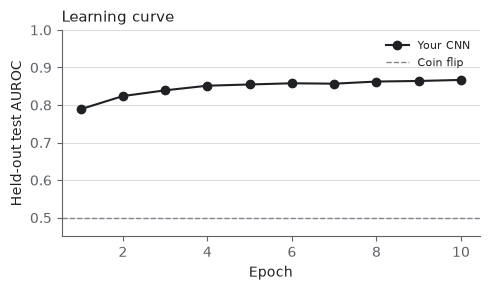

In [19]:
#@title Plot the learning curve - run this cell, nothing to change { display-mode: "form" }
import matplotlib.pyplot as plt
plt.figure(figsize=(5, 3))
plt.plot(range(1, len(history) + 1), history, marker="o", c=CNN_C, label="Your CNN")
plt.axhline(0.5, ls="--", c=MIDGREY, lw=1, label="Coin flip")
plt.xlabel("Epoch"); plt.ylabel("Held-out test AUROC"); plt.ylim(0.45, 1); plt.legend(); plt.grid(axis="y")
plt.title("Learning curve"); plt.tight_layout(); plt.show()

**Reading your result.** The curve should climb quickly and level off at about **0.86** (0.86 to
0.87). The test set has only 1,000
sequences, so any AUROC on it has a sampling uncertainty of about ±0.025 (95% range, part 1 talk).
A difference of 0.01 (0.85 against 0.86) is within this noise; a difference of 0.06 (0.80 against 0.86) is not.

## 5. Take your model with you

Each Colab notebook runs on its own machine. Download your trained CNN now. At the start of part 3
(`03_shortcuts_and_controls`) you can upload it, or use ours.

In [20]:
#@title Download my_cnn.pt - run this cell { display-mode: "form" }
download_outputs("my_cnn.pt")

my_cnn.pt: saved at /data/home/hoory/ai-days-2026/run_student/data/my_cnn.pt


# Look inside the CNN (sections 6 to 10)

Your CNN scores well, so it has picked up some signal that separates bound from unbound RNA. This
half asks what that signal is, and then tests the answer. The cells below use `model`, the CNN
you trained in section 4.

1. **Read a motif off the model.** Each first-layer filter scores every 10-letter window. We
   collect the windows where its output (its *activation*) is high and summarise them as a
   *sequence logo*.
2. **Test it.** The logo suggests what a filter responds to. We insert that motif into random RNA
   and check whether the model's score goes up.

## 6. The toolkit (given)

Read the names and descriptions. You will combine these functions in the TODOs below.

| function | what it does |
|---|---|
| `filter_activations(model, seqs)` | run only the first conv layer → `(n_seqs, n_filters, n_positions)` |
| `cutoff_for(acts_f)` | one filter's activation threshold: `mean + 0.5 × (max − mean)` |
| `windows_above(acts_f, seqs, cutoff)` | the 10-letter windows where that filter's activation exceeds the threshold |
| `pwm_of(windows)` | the frequency of each letter at each position → a `(10, 4)` table |
| `consensus_of(pwm)` | the most common letter at each position, as a string |
| `draw_logo(pwm, title)` | draw the table as a sequence logo |
| `random_rna(n, rng)` | `n` random RNA sequences of 330 letters to insert motifs into |
| `plant(seqs, motif, copies)` | insert `copies` copies of `motif` into each sequence (they overwrite letters) |
| `score_sequences(model, seqs)` | the model's probability of "bound" for each sequence (a numpy array) |

In [21]:
#@title Motif toolkit - run this cell, nothing to change { display-mode: "form" }
import logomaker
import matplotlib.pyplot as plt
import pandas as pd

CONV1 = next(l for l in model.net if isinstance(l, nn.Conv2d))
KERNEL = CONV1.kernel_size[1]          # read from the model, so a different width still works


@torch.no_grad()
def filter_activations(model, seqs, batch=512):
    """Run ONLY the first conv layer (+ReLU). Returns (n_seqs, n_filters, n_positions)."""
    conv1 = next(l for l in model.net if isinstance(l, nn.Conv2d))
    model.eval()
    out = []
    for i in range(0, len(seqs), batch):
        a = torch.relu(conv1(encode_batch(seqs[i:i + batch]).to(DEVICE)))
        out.append((a[:, :, 0, :] if a.shape[2] == 1 else a.amax(2)).cpu())  # (batch, filters, positions)
    return torch.cat(out).numpy()


def cutoff_for(acts_f):
    """The activation threshold for one filter: halfway between its mean and its maximum activation."""
    return acts_f.mean() + 0.5 * (acts_f.max() - acts_f.mean())


def windows_above(acts_f, seqs, cutoff):
    """Every KERNEL-letter window where this filter's activation exceeds the threshold (padding dropped)."""
    rows, cols = np.nonzero(acts_f > cutoff)
    out = [seqs[i][j:j + KERNEL] for i, j in zip(rows, cols)]
    return [w for w in out if len(w) == KERNEL and set(w) <= set(ALPHABET)]


def pwm_of(windows):
    """(KERNEL, 4) table: the frequency of each letter at each position."""
    arr = np.frombuffer("".join(windows).encode(), dtype=np.uint8).reshape(-1, KERNEL)
    counts = np.stack([(arr == ord(b)).sum(0) for b in ALPHABET], 1).astype(float)
    return counts / counts.sum(1, keepdims=True)


def consensus_of(pwm):
    return "".join(ALPHABET[i] for i in pwm.argmax(1))


def draw_logo(pwm, title="", ax=None):
    """Sequence logo in bits: one tall letter = conserved position; four short letters = no preference."""
    df = pd.DataFrame(pwm, columns=list(ALPHABET))
    info = logomaker.transform_matrix(df, from_type="probability", to_type="information")
    ax = ax or plt.subplots(figsize=(4, 1.6))[1]
    logomaker.Logo(info, ax=ax, color_scheme={b: BASE_COLOURS[b] for b in ALPHABET})
    ax.set_title(title, fontsize=9); ax.set_ylim(0, 2); ax.set_xticks([]); ax.set_ylabel("Bits", fontsize=8)
    return ax


def random_rna(n, rng, length=330):
    """n random RNA sequences (each letter equally likely), drawn with the random generator `rng`."""
    idx = rng.integers(0, 4, size=(n, length))
    return ["".join(ALPHABET[i] for i in row) for row in idx]


def plant(seqs, motif, copies=1, spacing=45, start=40):
    """Insert `copies` copies of `motif` into each sequence (overwriting letters), at letters
    40, 85, 130, ... A copy that would not fit inside a sequence is skipped."""
    out = []
    for s in seqs:
        s = list(s)
        for c in range(copies):
            at = start + c * spacing
            if at + len(motif) <= len(s):
                s[at:at + len(motif)] = list(motif)
        out.append("".join(s))
    return out


@torch.no_grad()
def score_sequences(model, seqs, batch=1024):
    """The model's binding probability for each sequence (list of RNA strings)."""
    model.eval()
    out = []
    for i in range(0, len(seqs), batch):
        X = encode_batch(seqs[i:i + batch])
        out.append(torch.sigmoid(model(X.to(DEVICE))).cpu().numpy())
    return np.concatenate(out)


print(f"toolkit ready (filter width = {KERNEL})")

toolkit ready (filter width = 10)


## 7. Read a motif off the model (TODO-4)

For each filter: compute its threshold, collect the windows above it, turn them into a letter
frequency table, and record its consensus (the most frequent letter at each position). You do this
first for one filter, filter 0, step by step (TODO-4a), then for every filter in a loop (TODO-4b).
Keep the tables; the cells after the test draw them.

In [22]:
#@title The activations of every filter on bound RNA - run this cell, nothing to change { display-mode: "form" }
pos_seqs = [s for s, y in zip(test_seqs, test_y) if y == 1] + \
           [s for s, y in zip(train_seqs, train_y) if y == 1][:5000]
acts = filter_activations(model, pos_seqs)
n_filters = acts.shape[1]
print("activations:", acts.shape, "-> (sequences, filters, positions) for", len(pos_seqs), "bound sequences")

activations: (5500, 10, 492) -> (sequences, filters, positions) for 5500 bound sequences


In [23]:
# TODO-4a: filter 0, step by step, with the toolkit of section 6. `acts` holds the activations of
#          every filter on the bound sequences `pos_seqs` (sequences, filters, positions). Produce:
#          acts_0       the activations of filter 0 only (one row per sequence, one column per position)
#          cut_0        filter 0's threshold
#          windows_0    the 10-letter windows of pos_seqs where filter 0 is above its threshold
#          pwm_0        the letter frequency table of these windows
#          consensus_0  the most frequent letter at each position
# === Your code here ===
...
# === End of your code ===
print("activations of filter 0:", acts_0.shape, f"| threshold {cut_0:.3f} (largest activation {acts_0.max():.3f})")
print(f"{len(windows_0):,} windows above the threshold; the first 5:", windows_0[:5])
print("\nletter frequency at each of the 10 positions (each row sums to 1):")
print(pd.DataFrame(pwm_0, columns=list(ALPHABET), index=range(1, KERNEL + 1)).round(2))
print("\nconsensus:", consensus_0)
draw_logo(pwm_0, f"Filter 00, {len(windows_0):,} windows")
plt.show()

NameError: name 'acts_0' is not defined

In [24]:
motifs, pwms, n_hits = {}, {}, {}
for f in range(n_filters):
    # TODO-4b: the steps of TODO-4a for filter f, stored as motifs[f] (the consensus),
    #          pwms[f] (the letter frequency table) and n_hits[f] (the number of windows).
    # === Your code here ===
    ...
    # === End of your code ===
    print(f"filter {f:02d}: {n_hits[f]:>7,} windows | consensus {motifs[f]}")

KeyError: 0

In [25]:
#@title Test TODO-4 - run this cell, nothing to change { display-mode: "form" }
def test_tables():
    for name, d in (("motifs", motifs), ("pwms", pwms), ("n_hits", n_hits)):
        assert sorted(d) == list(range(n_filters)), \
            f"{name} has the keys {sorted(d)}, want one entry for every filter 0 to {n_filters - 1}"
    for f in range(n_filters):
        a = acts[:, f, :]
        w = windows_above(a, pos_seqs, cutoff_for(a))
        ref = pwm_of(w)
        assert n_hits[f] == len(w), \
            (f"filter {f}: n_hits[{f}] = {n_hits[f]:,}, want {len(w):,}, the number of windows above the "
             f"threshold of filter {f} itself (its activations are acts[:, {f}, :])")
        P = np.asarray(pwms[f])
        assert P.shape == ref.shape, f"filter {f}: pwms[{f}] has shape {P.shape}, want {ref.shape} (positions x letters)"
        assert np.allclose(P, ref, atol=1e-6), \
            f"filter {f}: pwms[{f}] differs from pwm_of(its windows) by up to {np.abs(P - ref).max():.3g}"
        assert motifs[f] == consensus_of(ref), \
            f"filter {f}: motifs[{f}] = {motifs[f]!r}, want {consensus_of(ref)!r}, the consensus of pwms[{f}]"
    print(f"TODO-4 passed: window counts, letter tables and consensus match for all {n_filters} filters")


test_tables()

AssertionError: motifs has the keys [], want one entry for every filter 0 to 9

In [26]:
#@title Stuck? Run this only if the test failed: it builds the tables for you { display-mode: "form" }
motifs, pwms, n_hits = {}, {}, {}
for f in range(n_filters):
    acts_f = acts[:, f, :]
    windows = windows_above(acts_f, pos_seqs, cutoff_for(acts_f))
    pwms[f], n_hits[f] = pwm_of(windows), len(windows)
    motifs[f] = consensus_of(pwms[f])
test_tables()

TODO-4 passed: window counts, letter tables and consensus match for all 10 filters


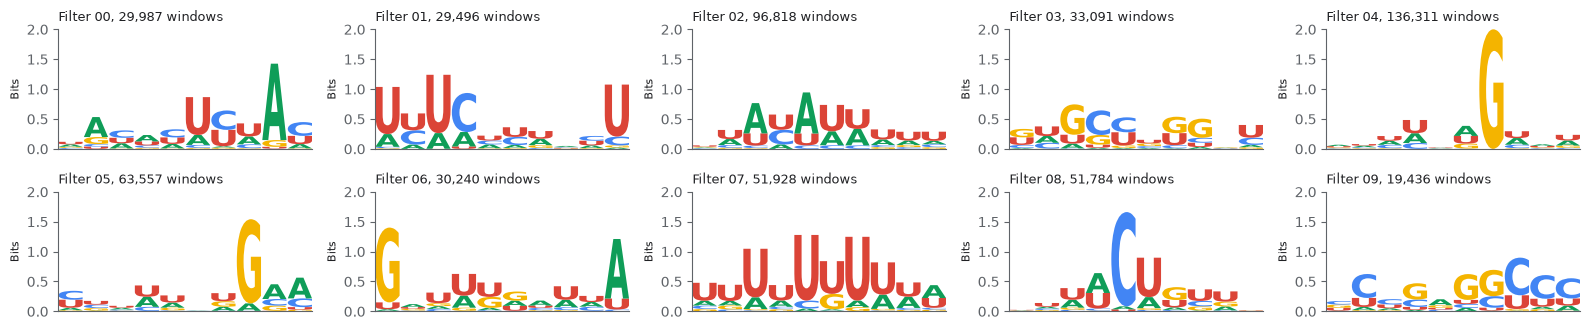

In [27]:
#@title Draw the logos - run this cell, nothing to change { display-mode: "form" }
cols = 5
rows = int(np.ceil(n_filters / cols))
fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 1.7 * rows))
for f, ax in zip(range(n_filters), axes.flat):
    draw_logo(pwms[f], f"Filter {f:02d}, {n_hits[f]:,} windows", ax)
for ax in list(axes.flat)[n_filters:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

**Reading a logo.** The height of a column is its information content in **bits**. 2 bits means
that every collected window has the same letter at that position; about 0 bits means all four
letters are about equally frequent there. Within a column, each letter's height is proportional to
its frequency in the collected windows.

**Choose a filter.** This is not a TODO, but the rest of the notebook uses it. Pick the filter whose
logo looks most like a specific pattern (tall, clean columns) and set `MY_FILTER` to its number.
`MY_MOTIF` is then its consensus, the tallest letter in each column from left to right. You can also
type the motif you read off the logo yourself. That string is your hypothesis for what the model
responds to. If you change nothing, you test filter 00.

In [28]:
MY_FILTER = 0                  # <- the number of the filter you chose
MY_MOTIF = motifs[MY_FILTER]   # its consensus; or type the motif you read off its logo (10 letters)
print(f"filter {MY_FILTER:02d} | testing the motif {MY_MOTIF}")

filter 00 | testing the motif UACACUCUAC


**A first control.** Run the same filter on **unbound** RNA. If it gives the same logo there, it picks
up a property of RNA in general (for example, how U-rich it is) and tells you little about AGO2. In
that case choose another filter, set `MY_FILTER` above, and rerun that cell and this one.

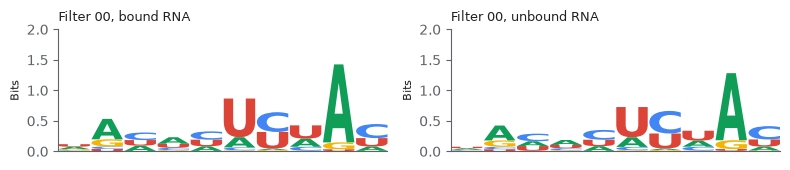

In [29]:
#@title The same filter on bound and on unbound RNA - run this cell { display-mode: "form" }
neg_seqs = [s for s, y in zip(test_seqs, test_y) if y == 0] + \
           [s for s, y in zip(train_seqs, train_y) if y == 0][:5000]
acts_neg = filter_activations(model, neg_seqs)
f = MY_FILTER
a_n = acts_neg[:, f, :]
pwm_neg = pwm_of(windows_above(a_n, neg_seqs, cutoff_for(a_n)))
fig, ax = plt.subplots(1, 2, figsize=(8, 1.8))
draw_logo(pwms[f], f"Filter {f:02d}, bound RNA", ax[0]); draw_logo(pwm_neg, f"Filter {f:02d}, unbound RNA", ax[1])
plt.tight_layout(); plt.show()

## 8. Now test it (TODO-5)

A logo shows which windows activate one filter. Whether that filter changes the model's *output* is a
separate question, and you answer it by intervening:

1. Score a batch of `random_rna` sequences: the **baseline**.
2. Insert your motif into the same sequences with `plant` (1, 2, … 7 copies) and score them again.
3. **Control:** do the same with a *shuffled* copy of your motif (same letters, different order).
   If the real motif raises the score and the shuffled one does not, the model is responding to the
   order of the letters as well as to which letters are present.

*(This shuffle only reorders the motif's 10 letters. Part 3 uses a stricter shuffle that keeps
every letter pair of a whole sequence.)*

You first insert one copy into one sequence (TODO-5a). Then you compute the **mean** score over all
random sequences for each number of copies, for the motif and for its shuffled copy (TODO-5b).

In [30]:
#@title The random sequences and the shuffled motif - run this cell, nothing to change { display-mode: "form" }
rng = np.random.default_rng(2)          # this cell's own random numbers, so a rerun gives the same result
canvas = random_rna(1000, rng)
baseline = score_sequences(model, canvas).mean()
shuffled = "".join(rng.permutation(list(MY_MOTIF)))
copies = list(range(1, 8))              # 7 copies fit into a 330-letter sequence
print(f"{len(canvas):,} random sequences of {len(canvas[0])} letters | mean score, nothing inserted: {baseline:.3f}")
print(f"motif {MY_MOTIF} | shuffled control {shuffled}")

1,000 random sequences of 330 letters | mean score, nothing inserted: 0.453
motif UACACUCUAC | shuffled control ACUUCCUAAC


In [31]:
# TODO-5a: one copy of MY_MOTIF in one sequence. `one` is the first random sequence of `canvas`;
#          `one_planted` is the same sequence with one copy of MY_MOTIF inserted (toolkit, section 6);
#          `score_before` and `score_after` are the model's scores of the two.
# === Your code here ===
...
# === End of your code ===
k = len(MY_MOTIF)
print("letters 21 to 80; the inserted letters (copy 1 starts at letter 41) in lower case:")
print("before:", one[20:80])
print("after :", one_planted[20:40] + one_planted[40:40 + k].lower() + one_planted[40 + k:80])
print(f"score before {score_before:.3f} | after {score_after:.3f}")

letters 21 to 80; the inserted letters (copy 1 starts at letter 41) in lower case:


NameError: name 'one' is not defined

In [32]:
# TODO-5b: for every number of copies in `copies`, the mean score over all sequences of `canvas`
#          with that many copies of MY_MOTIF inserted (`real_scores`), and the same with the
#          shuffled motif `shuffled` (`control_scores`): two lists, one number per number of copies.
# === Your code here ===
...
# === End of your code ===
print("motif   :", [round(float(v), 3) for v in real_scores])
print("shuffled:", [round(float(v), 3) for v in control_scores])

NameError: name 'real_scores' is not defined

In [33]:
#@title Test TODO-5 - run this cell, nothing to change { display-mode: "form" }
def test_insertion():
    for name, got, motif in (("real_scores", real_scores, MY_MOTIF), ("control_scores", control_scores, shuffled)):
        assert len(got) == len(copies), f"{name} has {len(got)} entries, want {len(copies)}: one per number of copies"
        want = [score_sequences(model, plant(canvas, motif, c)).mean() for c in copies]
        for c, g, w in zip(copies, got, want):
            n_copies = f"{c} copy" if c == 1 else f"{c} copies"
            g = np.asarray(g)
            assert g.size == 1, \
                f"{name}, {n_copies}: {g.size} numbers, want one, the mean score over the {len(canvas):,} sequences"
            g = float(g)
            assert 0 <= g <= 1, f"{name}, {n_copies}: {g:.3f} is not a probability between 0 and 1"
            assert abs(g - w) < 1e-6, \
                (f"{name}, {n_copies}: {g:.4f}, want {w:.4f}, the mean score over canvas with {n_copies} of "
                 f"{motif} inserted")
    print(f"TODO-5 passed: both lists have {len(copies)} mean scores between 0 and 1, equal to the reference")


test_insertion()

NameError: name 'real_scores' is not defined

In [34]:
#@title Stuck? Run this only if the test failed: it computes both lists for you { display-mode: "form" }
real_scores = [score_sequences(model, plant(canvas, MY_MOTIF, c)).mean() for c in copies]
control_scores = [score_sequences(model, plant(canvas, shuffled, c)).mean() for c in copies]
test_insertion()

TODO-5 passed: both lists have 7 mean scores between 0 and 1, equal to the reference


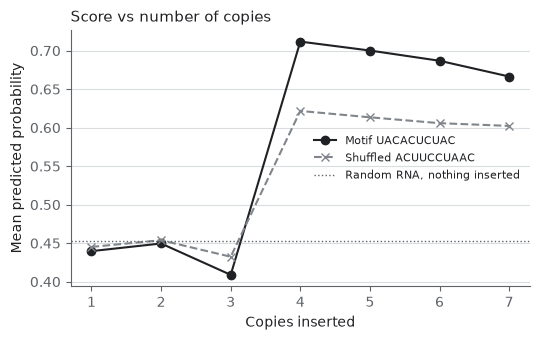

In [35]:
#@title Plot score vs number of copies - run this cell, nothing to change { display-mode: "form" }
plt.figure(figsize=(5.5, 3.5))
plt.plot(copies, real_scores, "o-", c=INK, label=f"Motif {MY_MOTIF}")
plt.plot(copies, control_scores, "x--", c=BASELINE_C, label=f"Shuffled {shuffled}")
plt.axhline(baseline, ls=":", c=MUTED, lw=1, label="Random RNA, nothing inserted")
plt.xlabel("Copies inserted"); plt.ylabel("Mean predicted probability"); plt.legend(); plt.grid(axis="y")
plt.title("Score vs number of copies"); plt.tight_layout(); plt.show()

**Reading your result.** Compare the two curves with each other. The shuffled copy can move the
score too, because it contains the same letters. If the curve jumps at one copy number,
suspect **position**: `plant()` writes copy 1 at letter 40, copy 2 at 85, copy 3 at 130, copy 4 at
175, and so on. The next cell checks this.

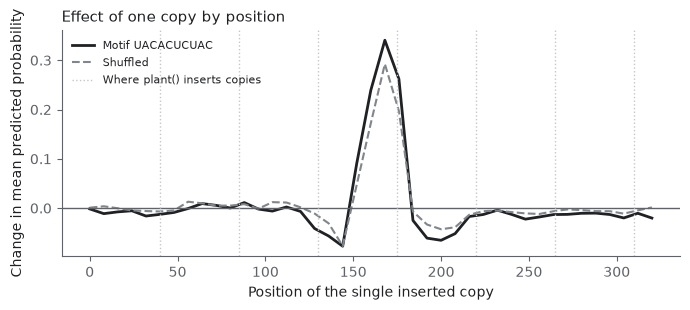

In [36]:
#@title Effect of one copy at each position - run this cell, nothing to change { display-mode: "form" }
# One copy of the motif at every position, 400 random sequences each; change in mean score vs no motif.
rng = np.random.default_rng(3)
positions = list(range(0, 321, 8))
scan_canvas = random_rna(400, rng)
base_scan = score_sequences(model, scan_canvas).mean()
real_scan = [score_sequences(model, [c[:x] + MY_MOTIF + c[x + len(MY_MOTIF):] for c in scan_canvas]).mean() - base_scan
             for x in positions]
shuf_scan = [score_sequences(model, [c[:x] + shuffled + c[x + len(shuffled):] for c in scan_canvas]).mean() - base_scan
             for x in positions]
plt.figure(figsize=(7, 3.2))
plt.plot(positions, real_scan, "-", lw=2, c=INK, label=f"Motif {MY_MOTIF}")
plt.plot(positions, shuf_scan, "--", c=BASELINE_C, label="Shuffled")
plt.axhline(0, c=MUTED, lw=1)
for x in (40, 85, 130, 175, 220, 265, 310):
    plt.axvline(x, c=LIGHTGREY, ls=":", lw=1, label="Where plant() inserts copies" if x == 40 else None)
plt.xlabel("Position of the single inserted copy"); plt.ylabel("Change in mean predicted probability")
plt.legend(); plt.title("Effect of one copy by position")
plt.tight_layout(); plt.show()

### What to take away

* The logo suggests a pattern. Inserting the motif, next to a shuffled control, tests whether the
  model's output responds to it.
* A strongly activated filter can still lower the score. Its effect on the output passes
  through every layer above it, so your curve can go down.
* If the logo looks the same on bound and unbound RNA, that filter picks up a property of RNA in
  general (for example, how U-rich it is) and tells you little about AGO2.
* The CNN's last layer has one weight per (filter, **position**). Almost every sequence in this data
  set, bound or unbound, was cut so that the measured ~40-letter site sits at letters 150–190, with
  context on both sides (the sequences are 137 to 375 letters long), and the CNN learned to weight
  that region. The shuffled copy gets much of the same increase there, so part of the effect
  comes from which letters occupy positions 150–190, whatever their order. A motif's effect on the score
  depends on where it is placed.

**Discuss with your neighbour:** did your motif score higher than its shuffled control? Did theirs?

## 9. Bonus (optional): known microRNA target sites

In [37]:
#@title Bonus (optional): insert known microRNA target sites - run this cell { display-mode: "form" }
# AGO2 carries a microRNA and binds RNA that base-pairs with the microRNA's "seed" (letters 2-7;
# these sites also pair letter 8). These sites are complementary to the seeds of a few abundant microRNAs. Each one is
# compared with 10 shuffled copies of itself.
rng = np.random.default_rng(4)
SITES = {"miR-15/16": "UGCUGCU", "miR-19": "UUUGCAC", "miR-30": "UGUUUAC", "let-7": "CUACCUC"}
neg_canvas = [s for s, y in zip(test_seqs, test_y) if y == 0]   # real unbound RNA as the canvas
base_neg = score_sequences(model, neg_canvas).mean()
print(f"unbound RNA, nothing inserted: {base_neg:.3f}   (6 copies inserted below; "
      f"shuffled = mean ± standard deviation over 10 shuffles)")
for name, site in SITES.items():
    r = score_sequences(model, plant(neg_canvas, site, 6)).mean()
    c = [score_sequences(model, plant(neg_canvas, "".join(rng.permutation(list(site))), 6)).mean() for _ in range(10)]
    print(f"{name:10s} site {site}: {r:.3f}   | shuffled: {np.mean(c):.3f} ± {np.std(c):.3f}   | difference {r - np.mean(c):+.3f}")

unbound RNA, nothing inserted: 0.292   (6 copies inserted below; shuffled = mean ± standard deviation over 10 shuffles)
miR-15/16  site UGCUGCU: 0.532   | shuffled: 0.286 ± 0.049   | difference +0.247


miR-19     site UUUGCAC: 0.394   | shuffled: 0.355 ± 0.062   | difference +0.040
miR-30     site UGUUUAC: 0.369   | shuffled: 0.315 ± 0.036   | difference +0.055


let-7      site CUACCUC: 0.389   | shuffled: 0.381 ± 0.045   | difference +0.008


**Reading the bonus result.** Compare each site with its own shuffled copies; the ± value is the
standard deviation over the 10 shuffles. With our reference CNN, only the miR-15/16 site (UGCUGCU)
raises the score well beyond the spread of its shuffled copies. The other three differ from their
shuffled copies by less than one standard deviation. The exact numbers depend on the random draw,
and a CNN trained from other random starting weights (yours, for example) may respond differently. Of the 6 copies,
only copy 4 (letter 175) lands in letters 150–190, the region the position scan showed the CNN
weights most. A copy that does not fit into a shorter sequence is skipped.

## 10. If you finish early

Change `EPOCHS` (e.g. 3 or 20) and rerun the training cell of section 4. Does more training still
help after epoch 10? Compare with your neighbour. (Keep the architecture as it is: part 3 loads this
exact shape.) The training cell saves each new model as `my_cnn.pt`; to take the new one to part 3,
run the download cell of section 5 again.